<a href="https://colab.research.google.com/github/anastasiatam/Engineering-with-Machine-Learning/blob/main/homework4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Question 1**

In [3]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from sklearn.model_selection import train_test_split
import numpy as np
import itertools

In [2]:
# Load the CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 861s 5us/step


In [4]:
# Save data
np.savez_compressed(
    'cifar10_dataset.npz',
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test,
)

# Load the dataset
data = np.load('cifar10_dataset.npz')

x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']

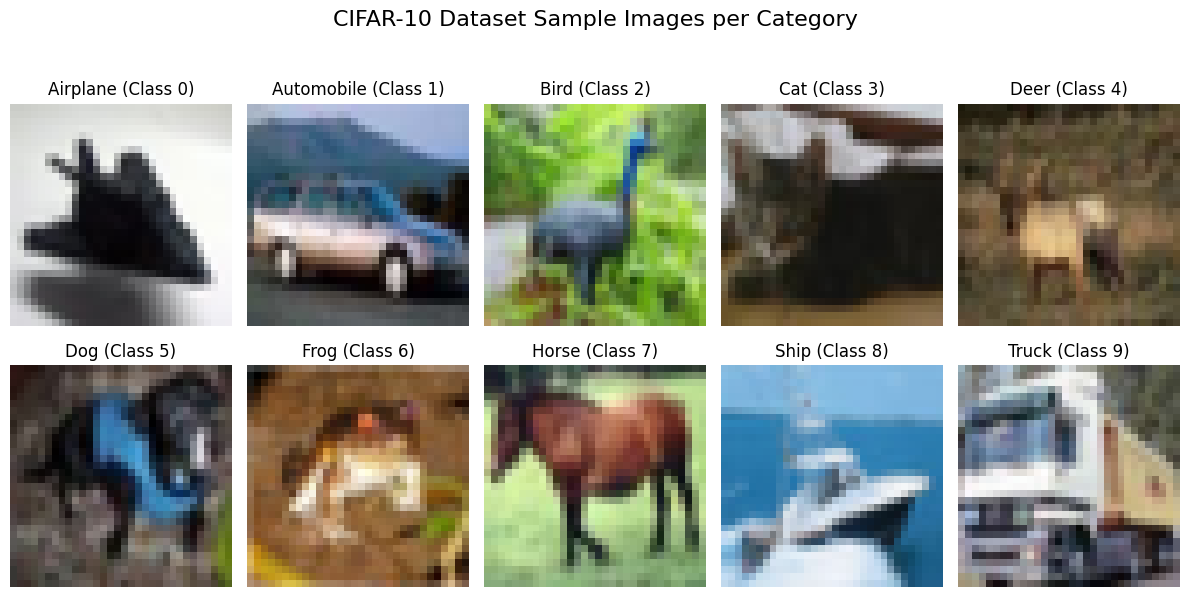

In [5]:
# ----------------------------------------
# --------------- PART A -----------------
# ----------------------------------------

# Define the corresponding class names for CIFAR-10
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

# Set up the plotting grid (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

# Loop through each category (0 to 9) and plot the first occurrence
for i in range(10):
    # Find the index of the first image belonging to class 'i'
    idx = np.where(y_train.flatten() == i)[0][0]

    # Display the image
    axes[i].imshow(x_train[idx])
    axes[i].set_title(f"{class_names[i]} (Class {i})", fontsize=12)
    axes[i].axis('off')

# Adjust layout and show the plot
plt.suptitle("CIFAR-10 Dataset Sample Images per Category", fontsize=16, y=1.03)
plt.tight_layout()
plt.show()

In [7]:
# ----------------------------------------
# --------------- PART B -----------------
# ----------------------------------------

# Normalize pixel values from [0, 255] to [0.0, 1.0]
x_train_normalized = x_train.astype('float32') / 255.0

# 70%-30% Training-Validation Split
x_train_set, x_val, y_train_set, y_val = train_test_split(
    x_train_normalized, y_train, test_size=0.30, random_state=42
)

print(f"Training set shape (70%): {x_train_set.shape}")
print(f"Validation set shape (30%): {x_val.shape}")

# Define Hyperparameter Grid
param_grid = {
    'hidden_layers': [
        [512, 256],          # Configuration A: Larger network
        [256, 128]           # Configuration B: Medium network
    ],
    'learning_rate': [0.001, 0.01],  # Optimizer learning rates
    'batch_size': [64, 128]          # Training batch sizes
}

# Generate all hyperparameter combinations
keys, values = zip(*param_grid.items())
grid_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0.0
best_params = None
best_model = None
best_history = None

# Execute Grid Search Loop
for i, params in enumerate(grid_combinations):
    print(f"\n--- Training Grid Combination {i+1}/{len(grid_combinations)} ---")
    print(f"Parameters: {params}")

    # Build Fully Connected Neural Network
    model = Sequential([
        Flatten(input_shape=(32, 32, 3))
    ])

    for units in params['hidden_layers']:
        model.add(Dense(units, activation='relu'))
        model.add(Dropout(0.3)) # Regularization dropout

    model.add(Dense(10, activation='softmax')) # 10 output classes

    # Compile Model
    optimizer = tf.keras.optimizers.Adam(learning_rate=params['learning_rate'])
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Train Model (set to 10 epochs for grid search demonstration)
    history = model.fit(
        x_train_set, y_train_set,
        validation_data=(x_val, y_val),
        epochs=10,
        batch_size=params['batch_size'],
        verbose=1
    )

    # Evaluate Validation Performance
    val_loss, val_acc = model.evaluate(x_val, y_val, verbose=0)
    print(f"Validation Accuracy for this run: {val_acc:.4f}")

    # Track the Best Performing Model and its Training History
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_params = params
        best_model = model
        best_history = history

# Final Summary of Grid Search
print("\n" + "="*50)
print("GRID SEARCH COMPLETED SUCCESSFULLY")
print("="*50)
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Best Hyperparameters: {best_params}")

Training set shape (70%): (35000, 32, 32, 3)
Validation set shape (30%): (15000, 32, 32, 3)

--- Training Grid Combination 1/8 ---
Parameters: {'hidden_layers': [512, 256], 'learning_rate': 0.001, 'batch_size': 64}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - accuracy: 0.2315 - loss: 2.0672 - val_accuracy: 0.3053 - val_loss: 1.9151
Epoch 2/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 23s 39ms/step - accuracy: 0.2748 - loss: 1.9497 - val_accuracy: 0.3429 - val_loss: 1.8213
Epoch 3/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 24s 43ms/step - accuracy: 0.2958 - loss: 1.9004 - val_accuracy: 0.3508 - val_loss: 1.8040
Epoch 4/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - accuracy: 0.3111 - loss: 1.8768 - val_accuracy: 0.3583 - val_loss: 1.8155
Epoch 5/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 41s 38ms/step - accuracy: 0.3198 - loss: 1.8546 - val_accuracy: 0.3765 - val_loss: 1.7603
Epoch 6/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.3267 - loss: 1.8332 - val_accuracy: 0.3727 - val_loss: 1.7781
Epoch 7/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.3295 - loss: 1.8254 - val_accuracy: 0.3863 - val_loss: 1.7330
Epoch 8/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.3353 - loss: 1.8120 - 

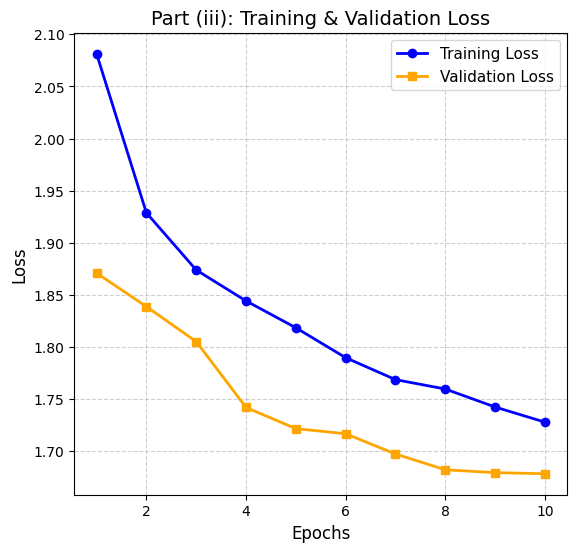

In [8]:
# ----------------------------------------
# --------------- PART C -----------------
# ----------------------------------------

# Extract metrics from the best-tuned model's training history
train_loss = best_history.history['loss']
val_loss = best_history.history['val_loss']
train_acc = best_history.history['accuracy']
val_acc_history = best_history.history['val_accuracy']
epochs_range = range(1, len(train_loss) + 1)

# Create plots for Losses and Accuracies side-by-side
plt.figure(figsize=(14, 6))

# Training and Validation Losses
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss, label='Training Loss', marker='o', color='blue', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='s', color='orange', linewidth=2)
plt.title('Part (iii): Training & Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

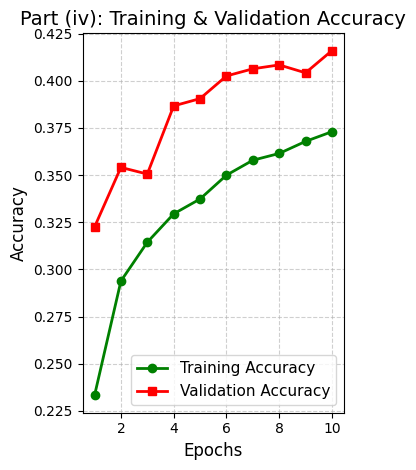

In [9]:
# ----------------------------------------
# --------------- PART D -----------------
# ----------------------------------------

# Training and Validation Accuracies
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc, label='Training Accuracy', marker='o', color='green', linewidth=2)
plt.plot(epochs_range, val_acc_history, label='Validation Accuracy', marker='s', color='red', linewidth=2)
plt.title('Part (iv): Training & Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# **Question 2**

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import io
from google.colab import files

In [19]:
data = files.upload()
# Automatically fetch the uploaded filename
filename = list(data.keys())[0]

Saving airfoil_self_noise.dat to airfoil_self_noise (1).dat


In [20]:
column_names = [
    'Frequency (Hz)',
    'Angle of Attack (deg)',
    'Chord Length (m)',
    'Free-Stream Velocity (m/s)',
    'Suction Side Displacement Thickness (m)',
    'Scaled Sound Pressure Level (dB)'
]

df = pd.read_csv(io.BytesIO(data[filename]), sep='\t', header=None, names=column_names)

print(f"\nSuccessfully loaded '{filename}'!")
print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 rows of the dataset:")
display(df.head())


Successfully loaded 'airfoil_self_noise (1).dat'!
Dataset Shape: (1503, 6)

First 5 rows of the dataset:


,Frequency (Hz),Angle of Attack (deg),Chord Length (m),Free-Stream Velocity (m/s),Suction Side Displacement Thickness (m),Scaled Sound Pressure Level (dB)
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461



Generating feature distribution histograms with units...


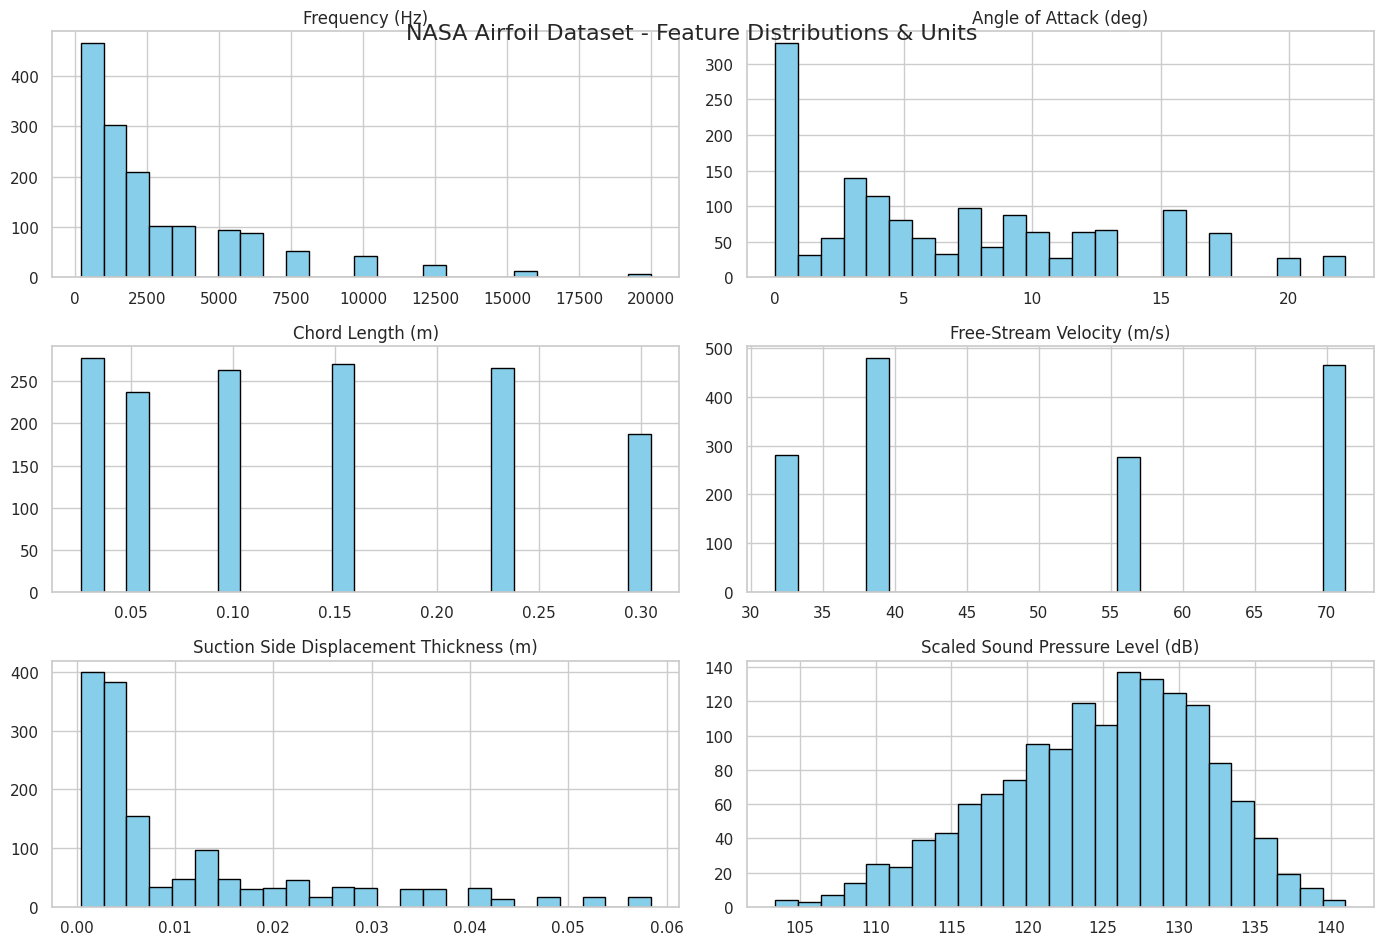

In [21]:
# ----------------------------------------
# --------------- PART A -----------------
# ----------------------------------------

# VISUALIZE DATASET DISTRIBUTIONS
print("\nGenerating feature distribution histograms with units...")
sns.set_theme(style="whitegrid")

# Plot histograms for all 6 attributes (titles will automatically display units)
df.hist(bins=25, figsize=(14, 10), color='skyblue', edgecolor='black')
plt.suptitle("NASA Airfoil Dataset - Feature Distributions & Units", fontsize=16, y=0.93)
plt.tight_layout()
plt.show()

Generating correlation matrix heatmap...


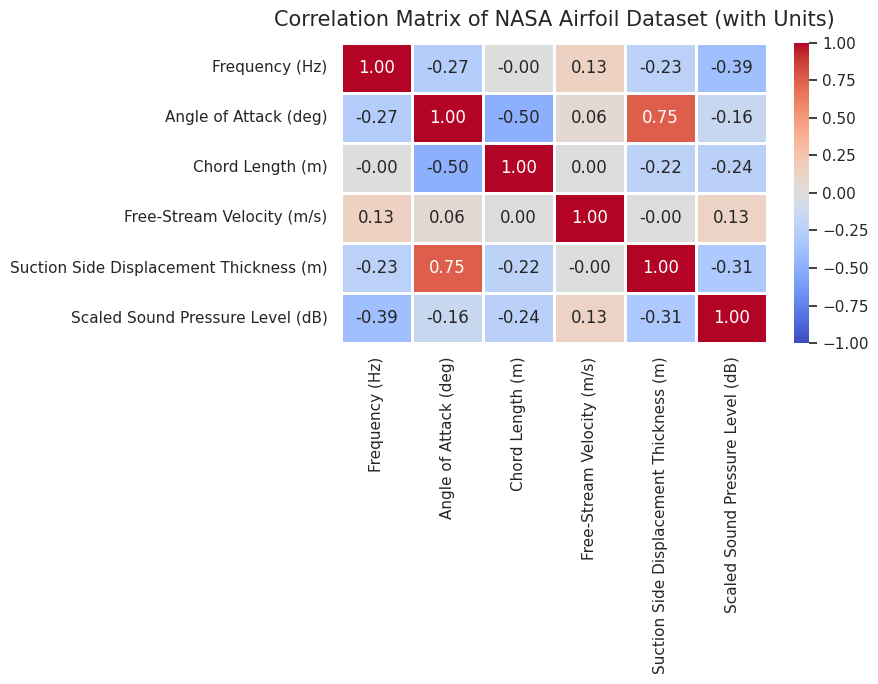

In [22]:
# VISUALIZE FEATURE CORRELATIONS
print("Generating correlation matrix heatmap...")
plt.figure(figsize=(9, 7))
correlation_matrix = df.corr()

# Create a heatmap with clear labels including units
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.8,
    vmin=-1, vmax=1
)
plt.title("Correlation Matrix of NASA Airfoil Dataset (with Units)", fontsize=15, pad=12)
plt.tight_layout()
plt.show()

In [28]:
# ----------------------------------------
# --------------- PART B -----------------
# ----------------------------------------

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt

# TUNE EXPERIMENT SETTINGS
LEARNING_RATE = 0.001
EPOCHS = 100
BATCH_SIZE = 32
HIDDEN_LAYER_SIZES = [256, 128, 64, 32]  # e.g., [128, 64, 32] for a 3-layer network

# DATA PREP
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# SPLIT & FEATURE SCALING
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# BUILD THE MODEL
model = Sequential()

# Input layer + first hidden layer
model.add(
    Dense(
        HIDDEN_LAYER_SIZES[0],
        activation='relu',
        input_shape=(X_train.shape[1],),
    )
)

# Add any additional hidden layers specified in HIDDEN_LAYER_SIZES
for units in HIDDEN_LAYER_SIZES[1:]:
  model.add(Dense(units, activation='relu'))

# Output layer for regression (1 neuron, no activation)
model.add(Dense(1))

# COMPILE MODEL
custom_optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)

model.compile(
    optimizer=custom_optimizer,
    loss='mean_squared_error',
    metrics=['mean_absolute_error'],
)

model.summary()

# TRAIN THE MODEL
history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_31 (Dense)                │ (None, 256)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,801 (175.00 KB)

 Trainable params: 44,801 (175.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 14159.5830 - mean_absolute_error: 118.5260 - val_loss: 9525.9639 - val_mean_absolute_error: 96.7933
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3126.5928 - mean_absolute_error: 45.5027 - val_loss: 633.7490 - val_mean_absolute_error: 20.4128
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 545.0007 - mean_absolute_error: 18.8277 - val_loss: 401.6243 - val_mean_absolute_error: 16.1145
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 386.4406 - mean_absolute_error: 15.8494 - val_loss: 334.5779 - val_mean_absolute_error: 14.6710
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 322.2559 - mean_absolute_error: 14.5302 - val_loss: 280.0877 - val_mean_absolute_error: 13.4265
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 274.4879 - mean_absolute_error: 13.3729 - val_loss: 239.2567 - val_mean_absolute_error: 12.4546
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 237.2

In [29]:
# ----------------------------------------
# --------------- PART C -----------------
# ----------------------------------------

from sklearn.metrics import r2_score

# Make predictions using the trained model on the 30% test set
y_pred = model.predict(X_test_scaled).flatten()

# Calculate the coefficient of determination (R^2 score)
r2 = r2_score(y_test, y_pred)

print("="*40)
print(f"Coefficient of Determination (R^2 Score): {r2:.4f}")
print("="*40)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Coefficient of Determination (R^2 Score): 0.7937
